<a href="https://colab.research.google.com/github/rlawhdqn-byte/trash/blob/main/trash_classfication_5756299_%EA%B9%80%EC%A2%85%EB%B6%80.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. 라이브러리 불러오기 및 시드 고정

In [3]:
import os
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("사용 중인 연산 장치:", device)

사용 중인 연산 장치: cuda


2.Kaggle 데이터셋 다운로드 및 데이터 증강 (Data Augmentation)

In [4]:
# 출처: https://www.kaggle.com/datasets/mostafaabla/garbage-classification
path = kagglehub.dataset_download("mostafaabla/garbage-classification")
DATA_DIR = os.path.join(path, "garbage_classification")
if not os.path.exists(DATA_DIR):
    DATA_DIR = path

print("데이터 경로:", DATA_DIR)

# 학습용 데이터 증강 (과적합 방지)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 검증/테스트용 전처리
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

full_dataset = datasets.ImageFolder(root=DATA_DIR)
class_names = full_dataset.classes
num_classes = len(class_names)
print(f"총 {num_classes}개 클래스: {class_names}")
print(f"전체 이미지 개수: {len(full_dataset)}장")

# Train(70%) / Val(15%) / Test(15%) 분할
total_size = len(full_dataset)
train_size = int(0.7 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

train_subset, val_subset, test_subset = random_split(full_dataset, [train_size, val_size, test_size])

class CustomSubset(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

train_dataset = CustomSubset(train_subset, transform=train_transform)
val_dataset = CustomSubset(val_subset, transform=val_transform)
test_dataset = CustomSubset(test_subset, transform=val_transform)

Using Colab cache for faster access to the 'garbage-classification' dataset.
데이터 경로: /kaggle/input/garbage-classification/garbage_classification
총 12개 클래스: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
전체 이미지 개수: 15515장


3.데이터 클래스 분포 그래프 (보고서 1장 삽입용)

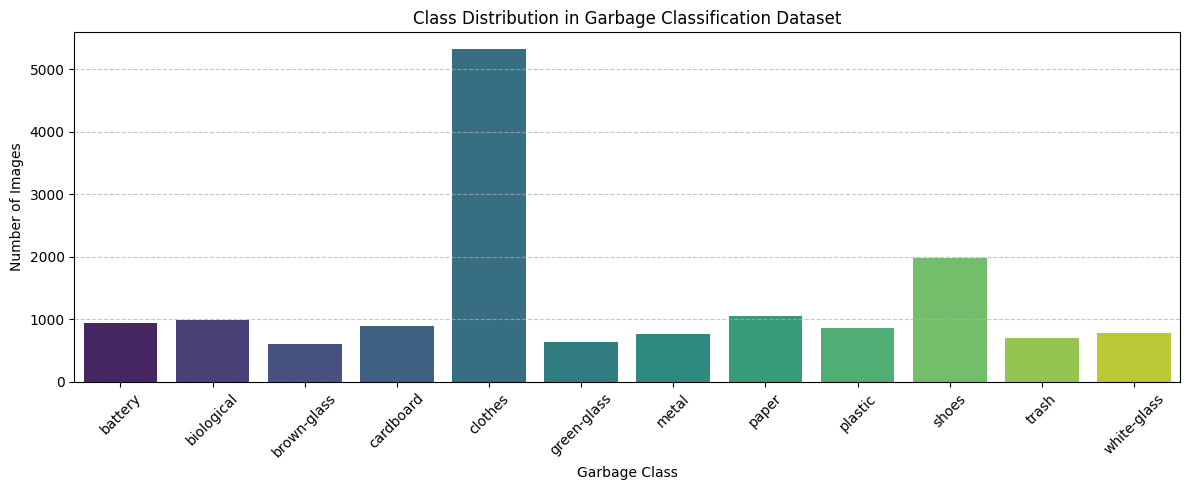

In [5]:
targets = [s[1] for s in full_dataset.samples]
class_counts = pd.Series(targets).value_counts().sort_index()

plt.figure(figsize=(12, 5))
sns.barplot(x=class_names, y=class_counts.values, hue=class_names, palette="viridis", legend=False)
plt.title("Class Distribution in Garbage Classification Dataset")
plt.xlabel("Garbage Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

4.순수 PyTorch 모델 정의 및 학습 함수 (과적합 방지 기법 포함)

In [6]:
def get_model(num_classes, dropout_rate=0.5):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(dropout_rate),
        nn.Linear(in_features, 256),
        nn.ReLU(),
        nn.Dropout(dropout_rate / 2),
        nn.Linear(256, num_classes)
    )
    return model.to(device)

def train_and_evaluate(config, epochs=10):
    train_loader = DataLoader(train_dataset, batch_size=config['batch_size'], shuffle=True, num_workers=2)
    val_loader = DataLoader(val_dataset, batch_size=config['batch_size'], shuffle=False, num_workers=2)

    model = get_model(num_classes, dropout_rate=config['dropout'])
    criterion = nn.CrossEntropyLoss()

    if config['optimizer'] == 'Adam':
        optimizer = optim.Adam(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    elif config['optimizer'] == 'SGD':
        optimizer = optim.SGD(model.parameters(), lr=config['lr'], momentum=0.9, weight_decay=config['weight_decay'])

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        train_loss = running_loss / total
        train_acc = 100. * correct / total

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * images.size(0)
                _, predicted = outputs.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()

        val_loss = val_loss / val_total
        val_acc = 100. * val_correct / val_total
        scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_wts = copy.deepcopy(model.state_dict())

        print(f"[{config['name']}] Epoch {epoch+1}/{epochs} | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}% | Val Loss: {val_loss:.4f}")

    model.load_state_dict(best_model_wts)
    return model, history, best_val_acc

5.하이퍼파라미터 비교 실험 (가점 핵심)

In [8]:
# 속도 최적화를 위한 128x128 Fast Transform (GPU 연산 속도 약 4배 향상)
fast_train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

fast_val_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset.transform = fast_train_transform
val_dataset.transform = fast_val_transform
test_dataset.transform = fast_val_transform

# AMP(혼합 정밀도)가 적용된 고속 학습 함수
def fast_train_and_evaluate(config, epochs=5):
    train_loader = DataLoader(train_dataset, batch_size=config['batch_size'], shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=config['batch_size'], shuffle=False, num_workers=2, pin_memory=True)

    model = get_model(num_classes, dropout_rate=config['dropout'])
    criterion = nn.CrossEntropyLoss()

    if config['optimizer'] == 'Adam':
        optimizer = optim.Adam(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    elif config['optimizer'] == 'SGD':
        optimizer = optim.SGD(model.parameters(), lr=config['lr'], momentum=0.9, weight_decay=config['weight_decay'])

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=1)
    scaler = torch.amp.GradScaler('cuda')

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            optimizer.zero_grad()
            with torch.amp.autocast('cuda'):
                outputs = model(images)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        train_loss = running_loss / total
        train_acc = 100. * correct / total

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
                with torch.amp.autocast('cuda'):
                    outputs = model(images)
                    loss = criterion(outputs, labels)
                val_loss += loss.item() * images.size(0)
                _, predicted = outputs.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()

        val_loss = val_loss / val_total
        val_acc = 100. * val_correct / val_total
        scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_wts = copy.deepcopy(model.state_dict())

        print(f"[{config['name']}] Epoch {epoch+1}/{epochs} | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}% | Val Loss: {val_loss:.4f}")

    model.load_state_dict(best_model_wts)
    return model, history, best_val_acc

experiments = [
    {"name": "Exp1_Adam_LR1e-3", "optimizer": "Adam", "lr": 1e-3, "batch_size": 64, "dropout": 0.3, "weight_decay": 1e-4},
    {"name": "Exp2_Adam_LR1e-4", "optimizer": "Adam", "lr": 1e-4, "batch_size": 64, "dropout": 0.5, "weight_decay": 1e-4},
    {"name": "Exp3_Adam_BS128",  "optimizer": "Adam", "lr": 1e-4, "batch_size": 128,"dropout": 0.5, "weight_decay": 1e-3},
    {"name": "Exp4_SGD_LR1e-2",  "optimizer": "SGD",  "lr": 1e-2, "batch_size": 64, "dropout": 0.5, "weight_decay": 1e-4},
]

results = {}
models_dict = {}
summary_list = []

for exp in experiments:
    print(f"\n================ {exp['name']} 시작 ================")
    trained_model, hist, best_acc = fast_train_and_evaluate(exp, epochs=5)
    results[exp['name']] = hist
    models_dict[exp['name']] = trained_model
    summary_list.append({
        "실험명": exp['name'],
        "Optimizer": exp['optimizer'],
        "Learning Rate": exp['lr'],
        "Batch Size": exp['batch_size'],
        "Dropout": exp['dropout'],
        "Weight Decay": exp['weight_decay'],
        "최고 검증 정확도(%)": round(best_acc, 2)
    })

summary_df = pd.DataFrame(summary_list)
display(summary_df)


================ Exp1_Adam_LR1e-3 시작 ================
[Exp1_Adam_LR1e-3] Epoch 1/5 | Train Acc: 73.83% | Val Acc: 74.95% | Val Loss: 0.9260
[Exp1_Adam_LR1e-3] Epoch 2/5 | Train Acc: 81.76% | Val Acc: 81.05% | Val Loss: 0.6185
[Exp1_Adam_LR1e-3] Epoch 3/5 | Train Acc: 84.46% | Val Acc: 84.57% | Val Loss: 0.5053
[Exp1_Adam_LR1e-3] Epoch 4/5 | Train Acc: 86.60% | Val Acc: 80.88% | Val Loss: 0.6755
[Exp1_Adam_LR1e-3] Epoch 5/5 | Train Acc: 87.41% | Val Acc: 84.36% | Val Loss: 0.5034

================ Exp2_Adam_LR1e-4 시작 ================
[Exp2_Adam_LR1e-4] Epoch 1/5 | Train Acc: 71.22% | Val Acc: 90.55% | Val Loss: 0.3141
[Exp2_Adam_LR1e-4] Epoch 2/5 | Train Acc: 89.70% | Val Acc: 92.52% | Val Loss: 0.2242
[Exp2_Adam_LR1e-4] Epoch 3/5 | Train Acc: 92.99% | Val Acc: 93.43% | Val Loss: 0.2045
[Exp2_Adam_LR1e-4] Epoch 4/5 | Train Acc: 95.22% | Val Acc: 92.74% | Val Loss: 0.2241
[Exp2_Adam_LR1e-4] Epoch 5/5 | Train Acc: 95.68% | Val Acc: 93.77% | Val Loss: 0.2195

================ Exp3_Adam_BS

,실험명,Optimizer,Learning Rate,Batch Size,Dropout,Weight Decay,최고 검증 정확도(%)
0,Exp1_Adam_LR1e-3,Adam,0.0010,64,0.3,0.0001,84.57
1,Exp2_Adam_LR1e-4,Adam,0.0001,64,0.5,0.0001,93.77
2,Exp3_Adam_BS128,Adam,0.0001,128,0.5,0.0010,93.90
3,Exp4_SGD_LR1e-2,SGD,0.0100,64,0.5,0.0001,94.07


6.하이퍼파라미터 비교, 과적합 점검 및 최종 Confusion Matrix 그래프

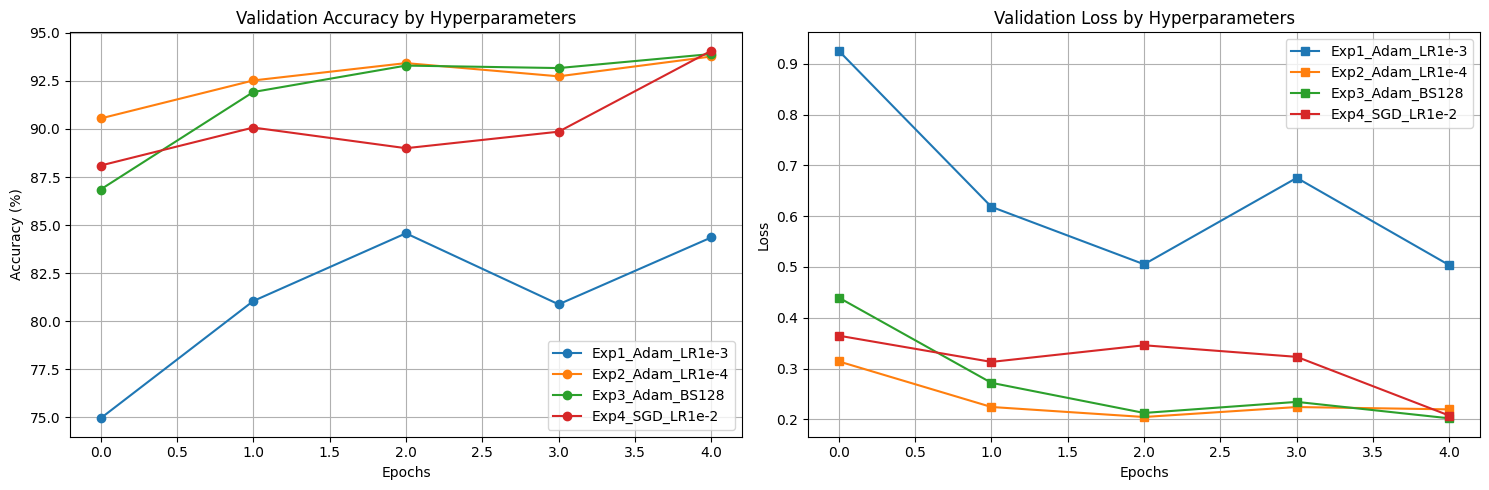

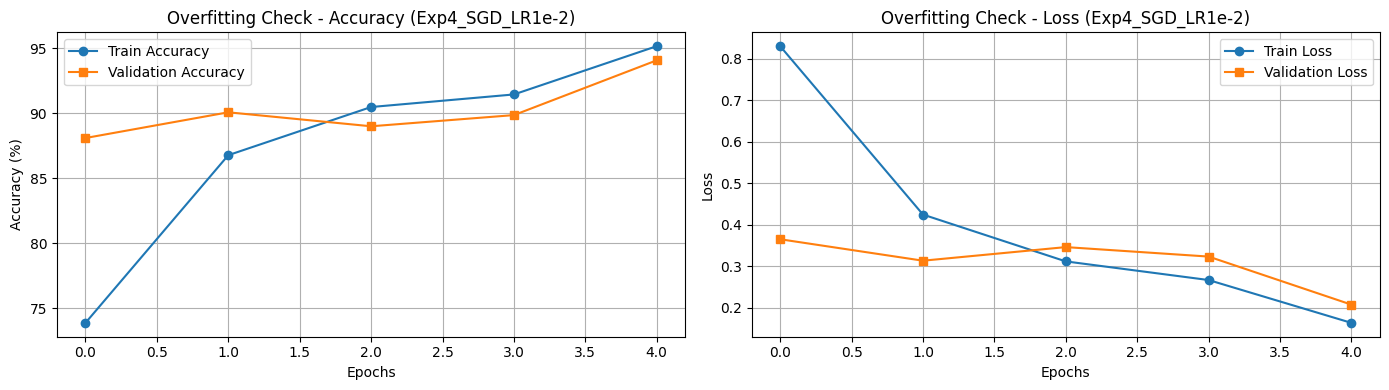


최종 선정 모델 (Exp4_SGD_LR1e-2) Test 평가 결과:
              precision    recall  f1-score   support

     battery       0.95      0.96      0.95       166
  biological       0.98      0.93      0.95       125
 brown-glass       0.97      0.97      0.97        95
   cardboard       1.00      0.92      0.96       121
     clothes       1.00      0.97      0.98       794
 green-glass       0.93      0.96      0.95       119
       metal       0.83      0.89      0.86       110
       paper       0.96      0.96      0.96       160
     plastic       0.77      0.86      0.81       120
       shoes       0.93      0.99      0.96       305
       trash       0.96      0.90      0.93       109
 white-glass       0.91      0.88      0.89       104

    accuracy                           0.95      2328
   macro avg       0.93      0.93      0.93      2328
weighted avg       0.95      0.95      0.95      2328



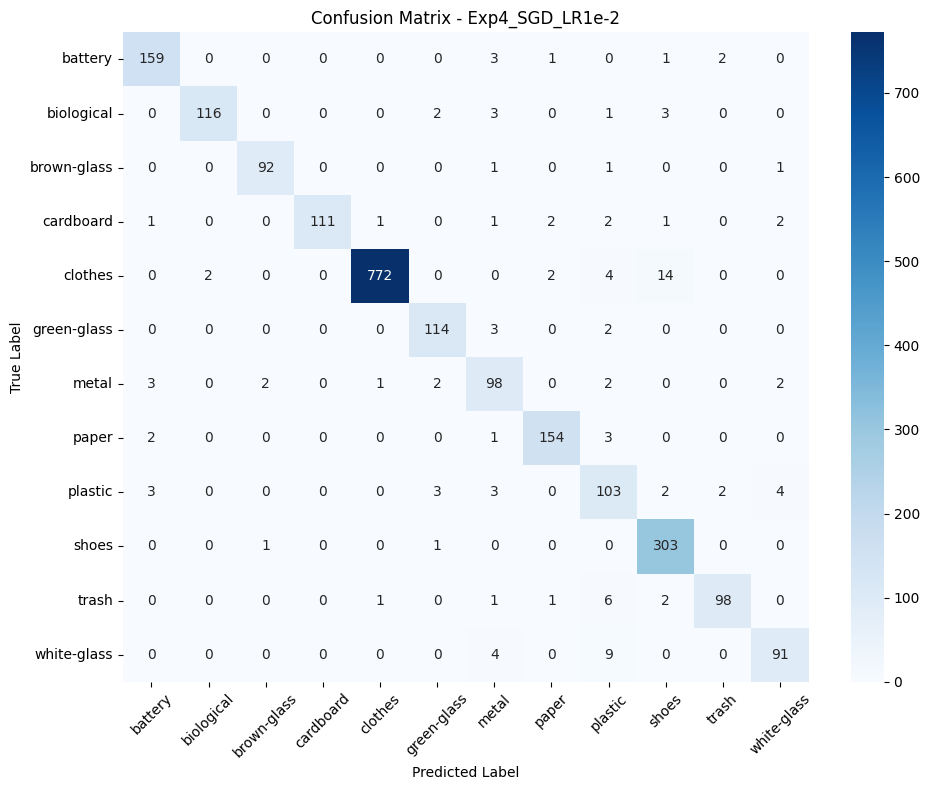

In [9]:
# 1. 하이퍼파라미터별 Validation Accuracy & Loss 비교 그래프
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, hist in results.items():
    axes[0].plot(hist['val_acc'], label=name, marker='o')
    axes[1].plot(hist['val_loss'], label=name, marker='s')

axes[0].set_title("Validation Accuracy by Hyperparameters")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Validation Loss by Hyperparameters")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# 2. 최고 성능 모델 선정 및 과적합 여부(Train vs Val) 그래프 출력
best_exp_name = summary_df.sort_values(by="최고 검증 정확도(%)", ascending=False).iloc[0]["실험명"]
best_hist = results[best_exp_name]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(best_hist['train_acc'], label='Train Accuracy', marker='o')
axes[0].plot(best_hist['val_acc'], label='Validation Accuracy', marker='s')
axes[0].set_title(f"Overfitting Check - Accuracy ({best_exp_name})")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(best_hist['train_loss'], label='Train Loss', marker='o')
axes[1].plot(best_hist['val_loss'], label='Validation Loss', marker='s')
axes[1].set_title(f"Overfitting Check - Loss ({best_exp_name})")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# 3. Test 데이터셋 최종 평가 및 Confusion Matrix
best_model = models_dict[best_exp_name]
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

best_model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = best_model(images)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print(f"\n최종 선정 모델 ({best_exp_name}) Test 평가 결과:")
print(classification_report(all_labels, all_preds, target_names=class_names))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion Matrix - {best_exp_name}")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

7.추가 데이터 결합 및 성능 비교

In [10]:
# ==============================================================================
# [셀 7] 추가 데이터셋(TrashNet) 결합 및 성능 향상 비교 실험
# 추가 데이터 출처: https://www.kaggle.com/datasets/feyzazkefe/trashnet
# ==============================================================================
from torch.utils.data import ConcatDataset
from PIL import Image

# 1. 추가 데이터셋 다운로드
extra_path = kagglehub.dataset_download("feyzazkefe/trashnet")
EXTRA_DIR = os.path.join(extra_path, "dataset-resized")
if not os.path.exists(EXTRA_DIR):
    for root, dirs, files in os.walk(extra_path):
        if "cardboard" in dirs and "plastic" in dirs:
            EXTRA_DIR = root
            break

print("추가 데이터 경로:", EXTRA_DIR)

# 2. 기본 데이터셋의 클래스 인덱스와 추가 데이터 클래스 매핑 (소수 클래스 5종 보충)
class_to_idx = full_dataset.class_to_idx
valid_extra_classes = ['cardboard', 'metal', 'paper', 'plastic', 'trash']

class ExtraGarbageDataset(Dataset):
    def __init__(self, root_dir, class_to_idx, valid_classes, transform=None):
        self.samples = []
        self.transform = transform
        for cls_name in valid_classes:
            cls_folder = os.path.join(root_dir, cls_name)
            if os.path.exists(cls_folder):
                target_idx = class_to_idx[cls_name]
                for fname in os.listdir(cls_folder):
                    if fname.lower().endswith(('.png', '.jpg', '.jpeg')):
                        self.samples.append((os.path.join(cls_folder, fname), target_idx))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, label

# [셀 5]에서 사용한 fast_train_transform(128x128)을 동일하게 적용
extra_train_dataset = ExtraGarbageDataset(EXTRA_DIR, class_to_idx, valid_extra_classes, transform=fast_train_transform)
print(f"추가 확보된 소수 클래스 학습 이미지 수: {len(extra_train_dataset)}장")

# 3. 기존 학습 데이터셋과 추가 데이터셋 병합 (Val/Test는 공정 비교를 위해 기존과 동일 유지)
combined_train_dataset = ConcatDataset([train_dataset, extra_train_dataset])
print(f"병합 후 총 학습 데이터 수: {len(train_dataset)}장 -> {len(combined_train_dataset)}장")

# 4. 기존 1등 하이퍼파라미터 설정으로 고속 재학습 (5 Epochs)
best_config = [exp for exp in experiments if exp['name'] == best_exp_name][0].copy()
best_config['name'] = best_exp_name + "_With_ExtraData"

combined_train_loader = DataLoader(combined_train_dataset, batch_size=best_config['batch_size'], shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=best_config['batch_size'], shuffle=False, num_workers=2, pin_memory=True)

extra_model = get_model(num_classes, dropout_rate=best_config['dropout'])
criterion = nn.CrossEntropyLoss()

if best_config['optimizer'] == 'Adam':
    optimizer = optim.Adam(extra_model.parameters(), lr=best_config['lr'], weight_decay=best_config['weight_decay'])
else:
    optimizer = optim.SGD(extra_model.parameters(), lr=best_config['lr'], momentum=0.9, weight_decay=best_config['weight_decay'])

scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=1)
scaler = torch.amp.GradScaler('cuda')

best_extra_val_acc = 0.0
best_extra_wts = copy.deepcopy(extra_model.state_dict())

for epoch in range(5):
    extra_model.train()
    train_correct, train_total = 0, 0
    for images, labels in combined_train_loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad()
        with torch.amp.autocast('cuda'):
            outputs = extra_model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        _, predicted = outputs.max(1)
        train_total += labels.size(0)
        train_correct += predicted.eq(labels).sum().item()

    extra_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with torch.amp.autocast('cuda'):
                outputs = extra_model(images)
                loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    val_loss /= val_total
    val_acc = 100. * val_correct / val_total
    scheduler.step(val_loss)

    if val_acc > best_extra_val_acc:
        best_extra_val_acc = val_acc
        best_extra_wts = copy.deepcopy(extra_model.state_dict())

    print(f"[추가데이터 적용] Epoch {epoch+1}/5 | Train Acc: {100.*train_correct/train_total:.2f}% | Val Acc: {val_acc:.2f}%")

# 5. 동일 Test 데이터셋에서 추가 데이터 적용 전/후 최종 정확도 비교
extra_model.load_state_dict(best_extra_wts)
extra_model.eval()

def evaluate_test_acc(target_model):
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = target_model(images)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
    return round(100. * correct / total, 2)

base_test_acc = evaluate_test_acc(best_model)
extra_test_acc = evaluate_test_acc(extra_model)

compare_extra_df = pd.DataFrame([
    {"구분": "기본 데이터셋만 사용 (Baseline)", "학습 데이터 수": len(train_dataset), "Test 정확도(%)": base_test_acc},
    {"구분": "추가 데이터셋 결합 (TrashNet 추가)", "학습 데이터 수": len(combined_train_dataset), "Test 정확도(%)": extra_test_acc}
])
display(compare_extra_df)

Using Colab cache for faster access to the 'trashnet' dataset.
추가 데이터 경로: /kaggle/input/trashnet/dataset-resized
추가 확보된 소수 클래스 학습 이미지 수: 2026장
병합 후 총 학습 데이터 수: 10860장 -> 12886장
[추가데이터 적용] Epoch 1/5 | Train Acc: 72.52% | Val Acc: 86.85%
[추가데이터 적용] Epoch 2/5 | Train Acc: 86.12% | Val Acc: 91.66%
[추가데이터 적용] Epoch 3/5 | Train Acc: 90.10% | Val Acc: 91.10%
[추가데이터 적용] Epoch 4/5 | Train Acc: 91.50% | Val Acc: 88.31%
[추가데이터 적용] Epoch 5/5 | Train Acc: 92.86% | Val Acc: 91.28%


,구분,학습 데이터 수,Test 정확도(%)
0,기본 데이터셋만 사용 (Baseline),10860,94.97
1,추가 데이터셋 결합 (TrashNet 추가),12886,91.97
